# Классификация опухолей молочной железы (Breast Cancer Wisconsin)

**Проект 1 из серии учебных ML-проектов по анализу онкологических данных.**

Цель проекта: построить модель бинарной классификации, которая по числовым характеристикам клеток опухоли определяет, является ли она **злокачественной (malignant)** или **доброкачественной (benign)**.

## Постановка задачи

| | |
|---|---|
| **Target (что предсказываем)** | 0 = malignant (злокачественная), 1 = benign (доброкачественная) |
| **Features (на основе чего)** | 30 числовых признаков клетки: радиус, текстура, периметр, площадь, гладкость границы и др. (в трёх вариантах — mean, error, worst) |
| **Тип задачи** | Supervised learning, бинарная классификация |
| **Ключевая метрика** | Recall для класса malignant — в медицине пропустить больного (False Negative) дороже, чем поднять ложную тревогу |


## Используемые библиотеки

- `pandas`, `numpy` — работа с табличными данными
- `matplotlib`, `seaborn` — визуализация
- `scikit-learn` — датасет, модель, метрики


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report
)

: 

## 1. Загрузка данных

Датасет Breast Cancer Wisconsin встроен в `scikit-learn` — не нужно ничего скачивать вручную. Он содержит данные 569 пациентов.

In [17]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print("Размер таблицы:", df.shape)
print("Классы:", data.target_names)

Размер таблицы: (569, 31)
Классы: ['malignant' 'benign']


**Важно:** порядок классов `['malignant' 'benign']` означает, что в данных **0 = malignant**, **1 = benign**. Это неинтуитивно и легко перепутать — держим в голове весь проект.

## 2. Разведочный анализ данных (EDA)

Прежде чем обучать модель, нужно понять данные: как они выглядят, есть ли технические проблемы (пропуски, неверные типы) и какие закономерности видны на глаз. Это отдельный этап, не связанный с "поиском слабых мест" — это база для всех дальнейших решений: какую модель выбрать, какие метрики важны, нужна ли предобработка.

In [18]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

**Вывод:** все 30 признаков — `float64`, `target` — `int64`, у всех колонок `569 non-null` — **пропусков нет**. Датасет чистый, предобработка пропущенных значений не требуется.

In [20]:
df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

**Баланс классов:** 357 benign / 212 malignant — примерно 63%/37%. Небольшой перекос, но не критичный. Из-за этого одна accuracy не даст полной картины — нужны precision/recall отдельно по каждому классу.

### 2.1 Визуализация — баланс классов

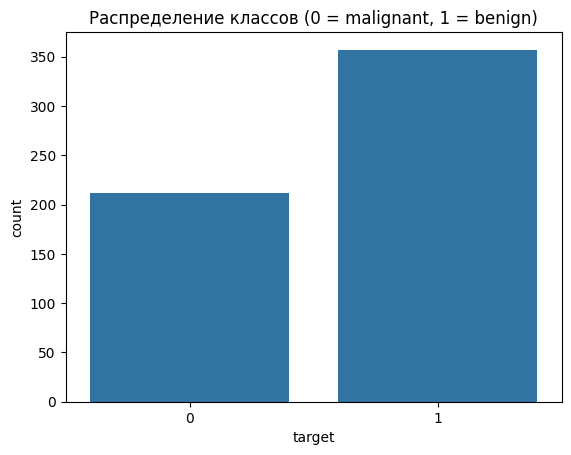

In [21]:
sns.countplot(x='target', data=df)
plt.title('Распределение классов (0 = malignant, 1 = benign)')
plt.show()

### 2.2 Визуализация — как признак разделяет классы

**Boxplot** ("ящик с усами"): прямоугольник — средние 50% значений, линия внутри — медиана, усы — разброс, точки — выбросы.

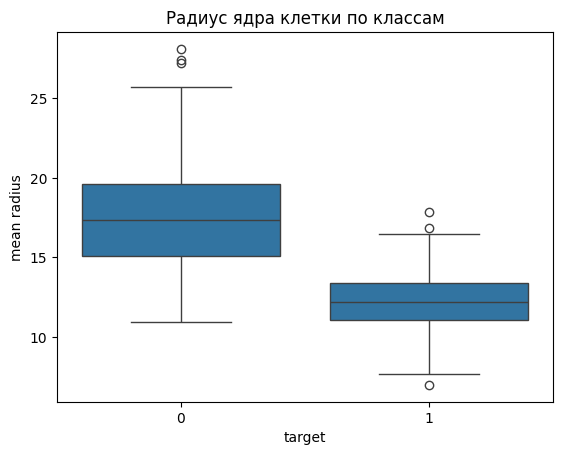

In [22]:
sns.boxplot(x='target', y='mean radius', data=df)
plt.title('Радиус ядра клетки по классам')
plt.show()

**Вывод:** "ящики" для malignant (медиана ~17.3) и benign (медиана ~12.2) почти не пересекаются — значит, `mean radius` сам по себе уже неплохо разделяет классы. Логично с медицинской точки зрения: раковые клетки чаще увеличены из-за нарушенного деления.

### 2.3 Визуализация — корреляции между всеми признаками

Каждая ячейка heatmap — коэффициент корреляции (от -1 до +1) между двумя признаками. Тёмно-красный — сильная положительная связь, синий — отрицательная.

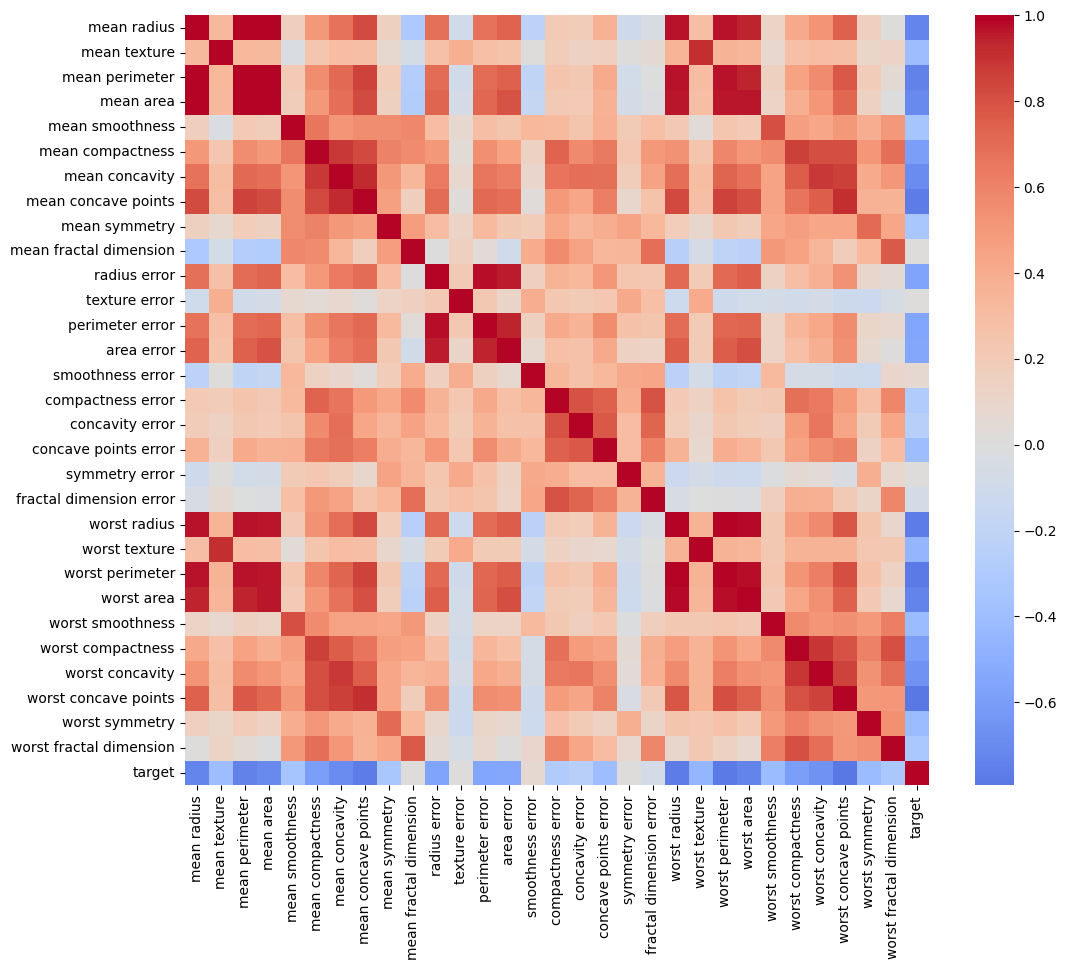

In [23]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.show()

**Выводы из heatmap:**

- **Мультиколлинеарность**: `mean radius`, `mean perimeter`, `mean area` коррелируют почти на 100% — это геометрически связанные величины (периметр ≈ 2πr, площадь ≈ πr²). Для логрегрессии это не фатально, но веса модели могут быть неустойчивы.
- **Связь с target**: столбец/строка `target` в основном синяя (отрицательная), потому что 0=malignant — чем больше признак (радиус, вогнутость и т.д.), тем ближе target к 0. Самые тёмные ячейки показывают признаки, сильнее всего связанные с диагнозом.

## 3. Разделение на train/test

Если проверять модель на тех же данных, на которых она обучалась, она может просто "запомнить" ответы (overfitting) — результат будет обманчиво хорошим. Поэтому:

- **train** (80%) — модель учится на этих данных
- **test** (20%) — модель их не видела вообще, на них честно проверяем качество

In [24]:
X = df.drop('target', axis=1)   # признаки — все колонки, кроме target
y = df['target']                # то, что предсказываем

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,    # фиксируем случайность для воспроизводимости
    stratify=y           # сохраняем то же соотношение классов в train и test
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(455, 30) (114, 30)
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


**`stratify=y`** — без этого параметра деление было бы полностью случайным, и пропорция классов могла бы "поплыть" (например в test случайно попало бы намного больше benign, чем в среднем по датасету). С `stratify=y` пропорция 63/37 сохраняется одинаковой и в train, и в test.

## 4. Стандартизация признаков

В данных признаки сильно различаются по масштабу: `mean area` ~ 1000, `mean smoothness` ~ 0.1. Для логистической регрессии это проблема — градиентный спуск обновляет веса пропорционально масштабу признака, и при таком разбросе масштабов обучение может идти нестабильно или медленно сходиться.

**StandardScaler** приводит каждый признак к среднему 0 и стандартному отклонению 1:

```
x_scaled = (x - mean(x)) / std(x)
```

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # считаем mean/std ПО TRAIN и сразу применяем
X_test_scaled = scaler.transform(X_test)          # применяем ТЕ ЖЕ mean/std к test

print(X_train_scaled.mean(axis=0)[:5])
print(X_train_scaled.std(axis=0)[:5])

[-4.31742554e-15  2.24606658e-15 -7.38359313e-16  1.71779562e-16
  5.22695440e-15]
[1. 1. 1. 1. 1.]


**Критически важный момент:** `fit_transform` вызывается только на train — mean и std считаются исключительно по обучающим данным. К test применяется `transform` с уже посчитанными на train значениями, без пересчёта.

**Почему не считать mean/std по всем данным сразу:** если использовать тестовые данные при вычислении статистики — это **data leakage** (утечка данных). Модель косвенно "узнаёт" о тесте до оценки, и метрики окажутся завышенными, не отражая реальное качество на новых данных.

## 5. Обучение модели — логистическая регрессия

Логистическая регрессия берёт линейную комбинацию признаков и пропускает через сигмоиду, чтобы получить вероятность от 0 до 1:

```
z = w1*x1 + w2*x2 + ... + wn*xn + b
p = 1 / (1 + e^(-z))
```

Обучение — это подбор весов `w` и смещения `b`, минимизирующих **log loss** (бинарную кросс-энтропию) на train-данных через градиентный спуск (в sklearn по умолчанию — метод L-BFGS).

In [26]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Предсказания:", y_pred[:10])
print("Реальность:  ", y_test.values[:10])

Предсказания: [0 1 0 1 0 1 1 0 0 0]
Реальность:   [0 1 0 1 0 1 1 0 0 0]


## 6. Метрики качества

Accuracy — не единственная и не самая важная метрика в медицинских задачах. Если 90% пациентов здоровы, модель, которая всегда говорит "здоров", уже даст 90% accuracy, но пропустит вообще всех больных.

- **Precision** — из всех, кого назвали positive, сколько реально positive
- **Recall** — из всех реально positive, скольких поймали. В онкологии критичнее всего **recall для malignant** — пропуск больного (False Negative) обходится дороже ложной тревоги.

In [27]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision (benign):", precision_score(y_test, y_pred))
print("Recall (benign):", recall_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=['malignant', 'benign']))

Accuracy: 0.9824561403508771
Precision (benign): 0.9861111111111112
Recall (benign): 0.9861111111111112

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [28]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[41  1]
 [ 1 71]]


**Confusion matrix** (0=malignant первый, по возрастанию значений класса):

```
              Предсказано malignant   Предсказано benign
Факт malignant        41                     1   <- пропущенный больной!
Факт benign             1                    71
```

При стандартном пороге 0.5 модель пропустила **1 из 42** malignant-случаев — хороший результат для учебного проекта (98% accuracy), но для реального медицинского применения даже такая ошибка считается риском.

## 7. Trade-off recall/precision — подбор порога классификации

По умолчанию модель предсказывает benign, если вероятность **p ≥ 0.5**. Мы можем сознательно повысить этот порог — тогда модель будет предсказывать benign только при высокой уверенности, а во всех сомнительных случаях — говорить malignant (отправлять на перепроверку).

In [29]:
y_proba = model.predict_proba(X_test_scaled)[:, 1]  # вероятность класса benign

for threshold in [0.5, 0.7, 0.9, 0.91]:
    y_pred_t = (y_proba >= threshold).astype(int)
    cm_t = confusion_matrix(y_test, y_pred_t)
    print(f"threshold = {threshold}")
    print(cm_t)
    print()

threshold = 0.5
[[41  1]
 [ 1 71]]

threshold = 0.7
[[41  1]
 [ 5 67]]

threshold = 0.9
[[41  1]
 [11 61]]

threshold = 0.91
[[42  0]
 [14 58]]



**Наблюдение по результатам (порог → confusion matrix):**

| Порог | Пропущено malignant | Ложных тревог у benign |
|---|---|---|
| 0.5 | 1 | 1 |
| 0.7 | 1 | 5 |
| 0.91 | 0 | 14 |

При пороге **0.91** модель не пропускает ни одного malignant-случая, но ценой этого — 14 здоровых пациентов ошибочно отправлены на перепроверку (precision malignant падает до 42/(42+14) ≈ 0.75).

**Вывод:** recall и precision нельзя одновременно довести до максимума — это фундаментальный trade-off. В реальных медицинских скрининговых системах порог почти всегда смещают в сторону recall: лишняя перепроверка — недорогая цена по сравнению с пропущенным раком. Выбор конкретного порога — это уже не чисто ML-решение, а вопрос клинической и экономической оценки цены каждого типа ошибки.

## Итоги проекта

1. Провели разведочный анализ данных (EDA): проверили пропуски, баланс классов, визуализировали распределения и корреляции.
2. Разделили данные на train/test со стратификацией по классам.
3. Стандартизировали признаки без утечки данных (fit только на train).
4. Обучили логистическую регрессию, получили 98% accuracy на test.
5. Разобрали, почему в медицинских задачах recall важнее общей accuracy.
6. Показали на практике trade-off между recall и precision через изменение порога классификации.

